# **1. SETUP and IMPORTS**


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,roc_auc_score, classification_report, confusion_matrix,roc_curve, auc)


from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings("ignore")

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
print("All libraries imported successfully")


All libraries imported successfully


# **2. LOAD DATASET**

In [ ]:
from google.colab import files
uploaded = files.upload()
file_name = list(uploaded.keys())[0]

print(f"Uploaded file: {file_name}")

bank_data = pd.read_csv(file_name)

print('Dataset shape:', bank_data.shape)
print('Columns:', bank_data.columns.tolist())
bank_data.head()

Saving Bank Marketing (1).csv to Bank Marketing (1).csv
Uploaded file: Bank Marketing (1).csv
Dataset shape: (41188, 21)
Columns: ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


# **3. DATA UNDERSTANDING and PREPARATION**

In [ ]:
TARGET_COLUMN = "y"
if TARGET_COLUMN not in bank_data.columns :   raise ValueError(f"Target Column '{TARGET_COLUMN}' not found in dataset")

bank_data["target_numeric"] = bank_data[TARGET_COLUMN].map({'yes': 1, "no": 0})
cleaned_data = bank_data.replace("unknown", np.nan)

missing_values = cleaned_data.isnull().sum()
print("Missing values per column: ")
print(missing_values[missing_values>0])

X = cleaned_data.drop([TARGET_COLUMN, "target_numeric"], axis=1)
y = cleaned_data["target_numeric"]

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()


print('Numeric features:', numeric_features)
print('Categorical features:', categorical_features)
print('Target distribution:')
print(y.value_counts())

Missing values per column: 
job           330
marital        80
education    1731
default      8597
housing       990
loan          990
dtype: int64
Numeric features: ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Target distribution:
target_numeric
0    36548
1     4640
Name: count, dtype: int64


# **4. EDA**

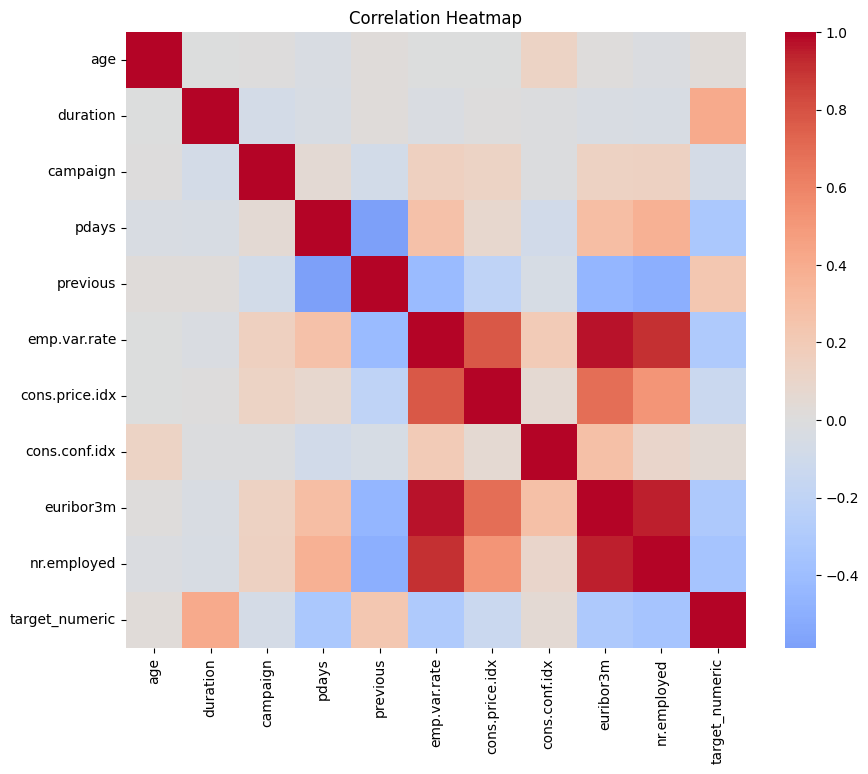

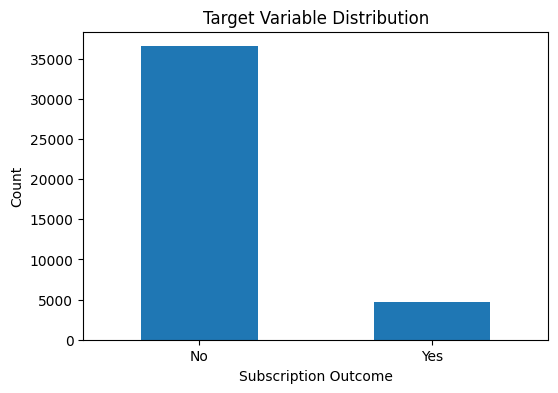

In [ ]:
plt.figure(figsize=(10,8))
numeric_data = cleaned_data.select_dtypes(include =["number"])
sns.heatmap(numeric_data.corr(), annot=False, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

plt.figure(figsize=(6,4))
y.value_counts().plot(kind="bar")

plt.title("Target Variable Distribution")
plt.xlabel("Subscription Outcome")
plt.ylabel("Count")
plt.xticks([0,1],["No", "Yes"], rotation=0)
plt.show()

# **5. TRAIN-TEST SPLIT and PREPROCESSING**

In [ ]:
X_train, X_test, y_train, y_test =train_test_split(X,y,test_size=0.2,random_state=RANDOM_SEED, stratify=y)

print(f"Training set: {X_train.shape}")
print(f"Testing set: {X_test.shape}")


preprocessor=ColumnTransformer(transformers=[('num', StandardScaler(), numeric_features),('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)])

preprocessor.fit(X_train)
X_train_processed = preprocessor.transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Data preprocessing completed successfully.")

Training set: (32950, 20)
Testing set: (8238, 20)
Data preprocessing completed successfully.


# 6. **MODEL EVALUATION FUNCTION**

In [ ]:
def evaluate_model(model, model_name, X_train, y_train, X_test, y_test):
  model.fit(X_train, y_train)

  y_pred = model.predict(X_test)
  y_proba = model.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba') else None


  accuracy = accuracy_score(y_test, y_pred)
  precision = precision_score(y_test, y_pred, zero_division=0)
  recall = recall_score(y_test, y_pred, zero_division=0)
  f1 = f1_score(y_test, y_pred, zero_division=0)
  roc_auc = roc_auc_score(y_test, y_proba) if y_proba is not None else None


  print(f"\n{model_name} Results:")
  print(f"Accuracy:  {accuracy:.4f}")
  print(f"Precision: {precision:.4f}")
  print(f"Recall:    {recall:.4f}")
  print(f"F1 Score:  {f1:.4f}")
  if roc_auc is not None:
    print(f"ROC AUC:   {roc_auc:.4f}")


  cm = confusion_matrix(y_test, y_pred)
  plt.figure(figsize=(5, 4))
  sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
  plt.title(f'Confusion Matrix - {model_name}')
  plt.ylabel('True Label')
  plt.xlabel('Predicted Label')
  plt.show()

  # ROC curve
  if y_proba is not None:
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], 'k--', label='Random classifier')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curve - {model_name}')
    plt.legend(loc='lower right')
    plt.show()

    return {
        "model": model_name,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": roc_auc
    }

# **7. LOGISTIC REGRESSION**


Logistic Regression Results:
Accuracy:  0.9166
Precision: 0.7118
Recall:    0.4364
F1 Score:  0.5411
ROC AUC:   0.9424


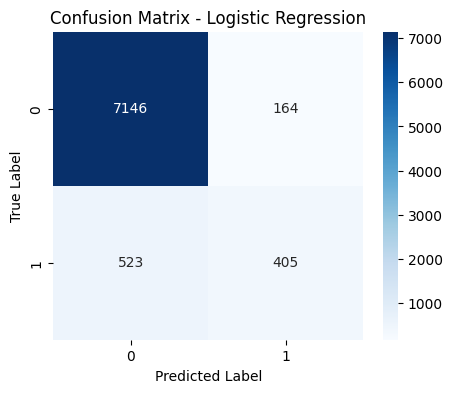

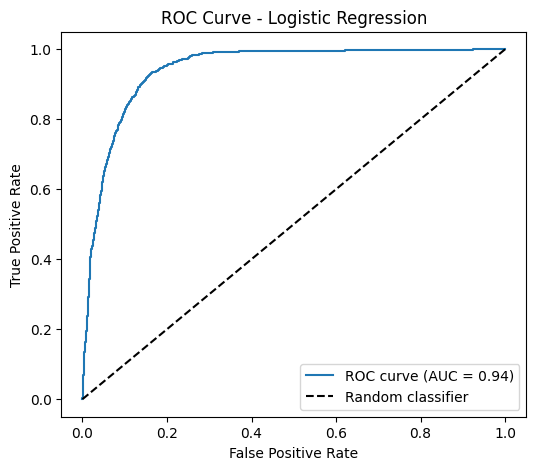

In [ ]:
#Model 1: Logistic Regression

logistic_regression = LogisticRegression(random_state=RANDOM_SEED, max_iter=1000)
logistic_results = evaluate_model(logistic_regression, "Logistic Regression", X_train_processed, y_train, X_test_processed, y_test)

# **8. DECISION TREE**


Decision Tree Results:
Accuracy:  0.8926
Precision: 0.5232
Recall:    0.5216
F1 Score:  0.5224
ROC AUC:   0.7306


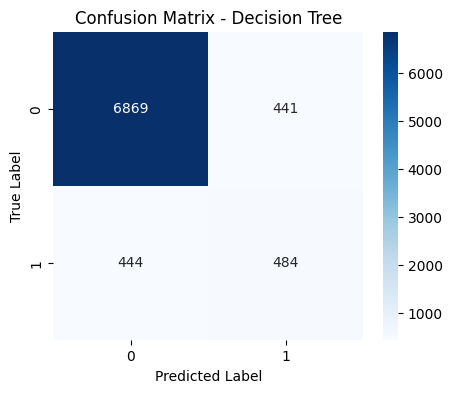

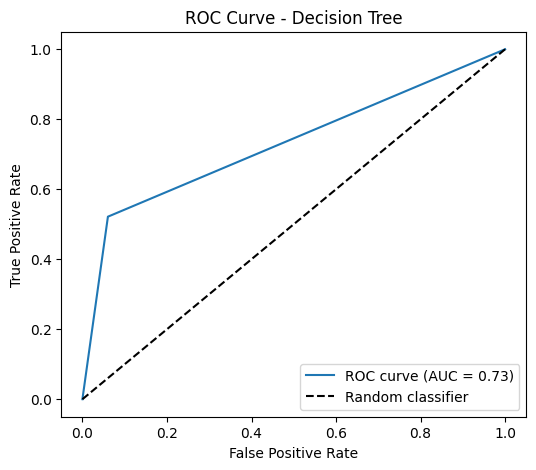

In [ ]:
# Model 2 : Decision tree
decision_tree = DecisionTreeClassifier(random_state=RANDOM_SEED)
decision_tree_results = evaluate_model(decision_tree, "Decision Tree", X_train_processed, y_train, X_test_processed, y_test)

# 9. **NEURAL NETWORK**


Neural Network Results:
Accuracy:  0.8951
Precision: 0.5436
Recall:    0.4300
F1 Score:  0.4801
ROC AUC:   0.9138


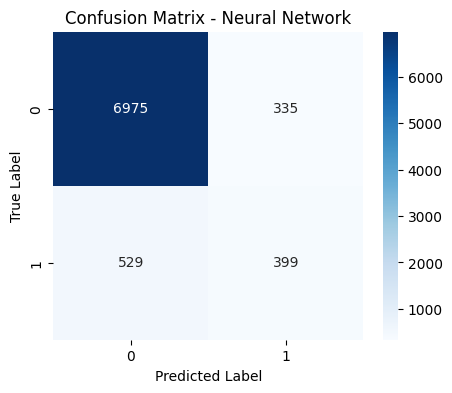

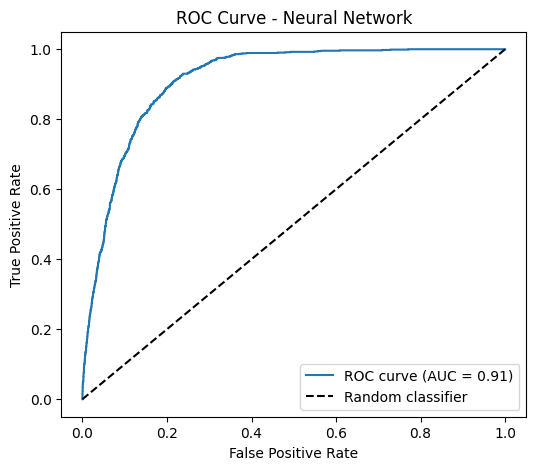

In [ ]:
# Model 3 : Neural Network

neural_network = MLPClassifier(hidden_layer_sizes=(64, 32), activation='relu', solver='adam', random_state=RANDOM_SEED, max_iter=500)
neural_network_results = evaluate_model(neural_network, "Neural Network", X_train_processed, y_train, X_test_processed, y_test)

# **10. COMPARISON of SUPERVISED MODELS**


Model Comparison:
                 model  accuracy  precision    recall        f1   roc_auc
0  Logistic Regression  0.916606   0.711775  0.436422  0.541082  0.942437
1        Decision Tree  0.892571   0.523243  0.521552  0.522396  0.730612
2       Neural Network  0.895120   0.543597  0.429957  0.480144  0.913790


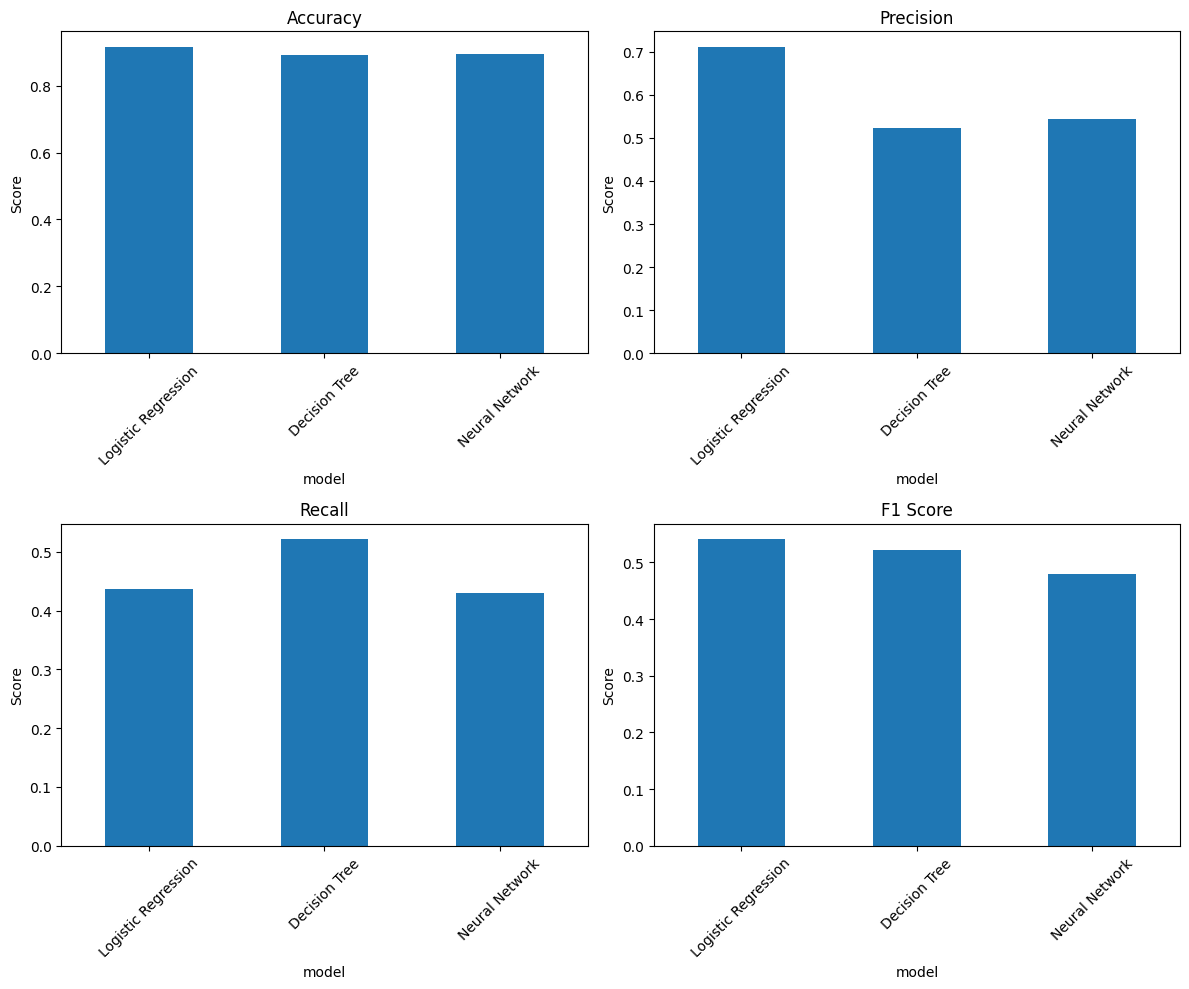

In [ ]:
results_comparison =pd.DataFrame([logistic_results, decision_tree_results, neural_network_results])

print("\nModel Comparison:")
print(results_comparison)

fig, axes = plt.subplots(2,2, figsize=(12,10))
metrics = ["accuracy", "precision", "recall", "f1"]
titles = ["Accuracy", "Precision", "Recall", "F1 Score"]

for i, (metric, title) in enumerate(zip(metrics, titles)):
  ax = axes[i//2,i%2]
  results_comparison.plot(x="model", y=metric, kind="bar", ax=ax, legend=False)
  ax.set_title(title)
  ax.set_ylabel("Score")
  ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

# **11. UNSUPERVISED LEARNING : KMEANS CLUSTERING**

Cluster distribution:
1    22099
0    10851
Name: count, dtype: int64

Cluster vs Actual distribution:
actual       0     1
cluster             
0         8228  2623
1        21010  1089


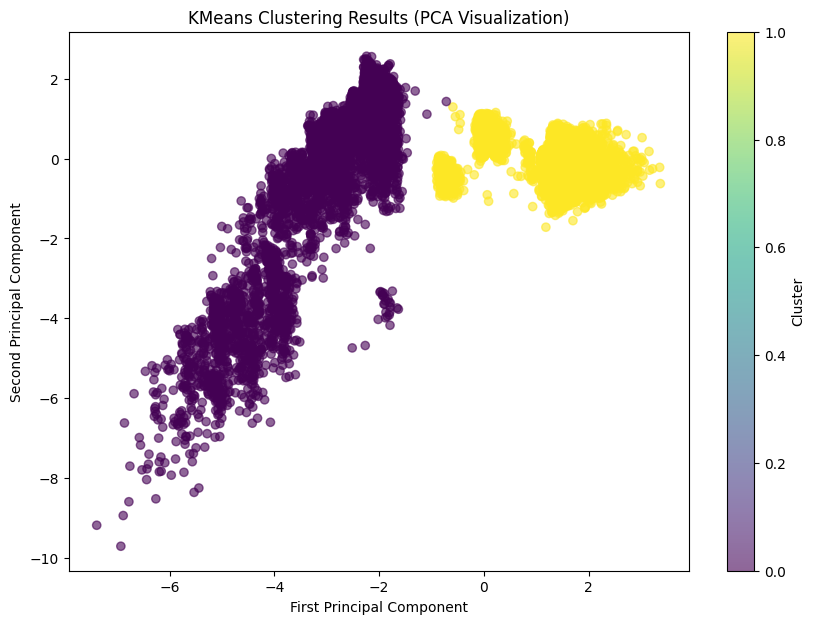

In [ ]:
#KMeans CLustering

kmeans = KMeans(n_clusters=2, random_state=RANDOM_SEED, n_init=10)
clusters = kmeans.fit_predict(X_train_processed)
print("Cluster distribution:")
print(pd.Series(clusters).value_counts())


cluster_comparison = pd.DataFrame({"cluster": clusters,"actual": y_train.values})

print("\nCluster vs Actual distribution:")
print(pd.crosstab(cluster_comparison["cluster"], cluster_comparison["actual"]))

pca = PCA(n_components=2, random_state=RANDOM_SEED)

if hasattr(X_train_processed, "toarray"):
  X_pca = pca.fit_transform(X_train_processed.toarray())
else:
  X_pca = pca.fit_transform(X_train_processed)

plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, cmap='viridis', alpha=0.6)
plt.colorbar(scatter, label="Cluster")
plt.xlabel("First Principal Component")
plt.ylabel("Second Principal Component")
plt.title("KMeans Clustering Results (PCA Visualization)")
plt.show()